# Approximate Piecewise Linear Function by single hidden layer neural networks with ReLU 

Define a piecewise-linear function $u : {\mathbb{R}} \rightarrow {\mathbb{R}}$ as follows.

Given finitely many points $x_1 < x_2 < ... < x_n$, define

$u(x) = \alpha_1 x + \beta_1$, for $x \le x_1$

$u(x) = \alpha_2 x + \beta_2$, for $x_1 \le x \le x_2$

$u(x) = \alpha_i x + \beta_i$, for $x_i \le x \le x_{i+1}$

$u(x) = \alpha_{n+1} x + \beta_{n+1}$, for $x_n \le x$

where $\alpha_i , \beta_i \in {\mathbb{R}}$.
We impose the continuity conditions
$$
\alpha_i x_i + \beta_i = \alpha_{i+1} x_i + \beta_{i+1}
\quad \Rightarrow \quad
\beta_{i+1}= (\alpha_i - \alpha_{i+1}) x_i + \beta_i
$$
Then we can fit $u(x)$ exactly by a neural network $f \in N_2(1,d,1,ReLU,Id)$, with hidden dimension $d = n+1$.

### Constructive solution:

Choose $(x_1, y_1)$, with $y_1 = \alpha_1 x_1 + \beta_1 = \alpha_2 x_1 + \beta_2$ as our "anchor point".

Define $g_1 (x) = - \alpha_1 ReLU( x_1 - x) + y_1$.
Then, for $x \le x_1$, 
$$
g_1(x) = -\alpha_1 (x_1 - x) + y_1
= 
\alpha_1 (x - x_1) + \alpha_1 x_1 + \beta_1 = \alpha_1 x + \beta_1 = u(x)$$
So $g_1(x) = u(x)$ for $x \le x_1$, and $g_1 (x) = y_1$ for $x_1 \le x$. 

Now define $g_2 (x) = g_1 (x) + \alpha_2 ReLU(x - x_1)$.

For $x \le x_1$, $g_2 (x) = g_1 (x) = u(x)$, and for $x_1 \le x$, then 
$$g_2 (x) = y_1 + \alpha_2 (x - x_1) = \alpha_2 x_1 + \beta_2 + \alpha_2 (x - x_1) = \alpha_2 x + \beta_2$$
So $g_2(x) = u(x)$ for $x \le x_2$.

Next define $g_3 (x) = g_2 (x) + (\alpha_3 - \alpha_2) ReLU(x - x_2)$. You can check that $g_3 (x) = u(x)$ for $x \le x_3$.

For $i = 2, \ldots , n$, define 
$$g_{i+1} (x) = g_i (x) + (\alpha_{i+1} - \alpha_i) ReLU(x - x_i)$$

Then for $x \le x_i$, $g_{i+1} (x) = g_i (x) = u(x)$ (by induction), and you can check that $g_{i+1} (x) = u(x)$ for $x_i \le x \le x_{i+1}$ also.
Hence
$$u (x) = - \alpha_1 ReLU( x_1 - x) + y_1 + \alpha_2 ReLU(x - x_1) + \sum_{j=2}^n (\alpha_{j+1} - \alpha_j) ReLU (x - x_j)$$
$$\Rightarrow \quad u(x) = W^2 ReLU( W^1 x + b^1) + b^2 \quad \quad \forall \quad x$$
where $W^1 = [-1, 1, \ldots , 1]^t$, $b^1 = [x_1, -x_1, \ldots , -x_n ]^t$,
$W^2 = [ - \alpha_1 , \alpha_2 , (\alpha_3 - \alpha_2) , \ldots, (\alpha_{n+1} - \alpha_n)]$, $b^2 = y_1$.
We illustrate this below:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [2]:
def ReLU(x):
    return max(x,0.0)

# Apply the function using np.vectorize
vec_ReLU = np.vectorize(ReLU)

In [3]:
# generate some random, but self-consistent, x_i, alpha_i, beta_i

max_n = 7
min_n = 3
n = np.random.randint(min_n, max_n + 1)
n = 7
print("n = ", n)

this_scale = 0.1
initial_x_i = np.arange(-3., 4. , 1.) + np.random.uniform(-this_scale, this_scale, n)

print("initial_x_i = ", initial_x_i)
sorted_x_i_vals = np.sort(initial_x_i)
print("sorted_x_i_vals = ", sorted_x_i_vals)

alpha_vals = np.zeros(len(sorted_x_i_vals)+1)
alpha_vals[0] = -1 * np.random.uniform(1,2)
for i in range(1, len(alpha_vals)):
    alpha_vals[i] = -1 * alpha_vals[i-1] + np.random.uniform(-2.0, 2.0)

beta_vals = np.zeros(len(alpha_vals))
beta_vals[0] = np.random.uniform(-1,1)
print("beta_vals = ", beta_vals)
for i in range(0, len(beta_vals) - 1):
    term_one = (alpha_vals[i] - alpha_vals[i+1])
    term_two = term_one * sorted_x_i_vals[i]
    term_three = term_two + beta_vals[i]
    beta_vals[i+1] = term_three 

eps = 10**-8
# sanity check
for i in range(len(sorted_x_i_vals)):
    first = (alpha_vals[i] * sorted_x_i_vals[i]) + beta_vals[i]
    second = (alpha_vals[i+1] * sorted_x_i_vals[i]) + beta_vals[i+1]
    print(i, first, second, abs(first - second) < eps)


n =  7
initial_x_i =  [-3.06697999 -2.03425779 -1.06883383  0.03046068  1.02420338  2.00561466
  2.97535283]
sorted_x_i_vals =  [-3.06697999 -2.03425779 -1.06883383  0.03046068  1.02420338  2.00561466
  2.97535283]
beta_vals =  [0.18331722 0.         0.         0.         0.         0.
 0.         0.        ]
0 5.995854109649541 5.995854109649541 True
1 9.000804083315941 9.000804083315943 True
2 6.92440580719447 6.92440580719447 True
3 11.111491116495031 11.111491116495031 True
4 8.5455195103391 8.545519510339098 True
5 11.405895166753501 11.4058951667535 True
6 7.5535213401226 7.5535213401225985 True


In [4]:
def u(these_sorted_x_i_vals : np.ndarray, 
      alpha_vals : np.ndarray, 
      beta_vals : np.ndarray,
      x : float) -> float:
    if x <= these_sorted_x_i_vals[0]:
        return alpha_vals[0] * x + beta_vals[0]
    for i in np.arange(1, len(these_sorted_x_i_vals)):
        if x <= these_sorted_x_i_vals[i]:
            return alpha_vals[i] * x + beta_vals[i]

    return alpha_vals[-1] * x + beta_vals[-1]

# Apply the function using np.vectorize
vec_u = np.vectorize(u)

In [5]:
# calculate the values of u(x)

max_x_i = 5.0
min_x_i = -5.0

num_x_vals = 1001
x_vals = np.linspace(min_x_i - 2.0, max_x_i + 2.0, num_x_vals)

test_sorted_x_i_vals = [-2., -1., 0., 1., 2.]
test_alpha_vals = [1., -1., 1., -1., 1., -1.]
test_beta_vals = [2., -2., 0., 0., -2., 2.]

print("sorted_x_i_vals = ", sorted_x_i_vals, type(sorted_x_i_vals))

i=0
u_vals = np.zeros(len(x_vals))
for x in x_vals:
    u_vals[i] = u(sorted_x_i_vals, alpha_vals, beta_vals, x)
    i +=1

sorted_x_i_vals =  [-3.06697999 -2.03425779 -1.06883383  0.03046068  1.02420338  2.00561466
  2.97535283] <class 'numpy.ndarray'>


num_g_i =  8


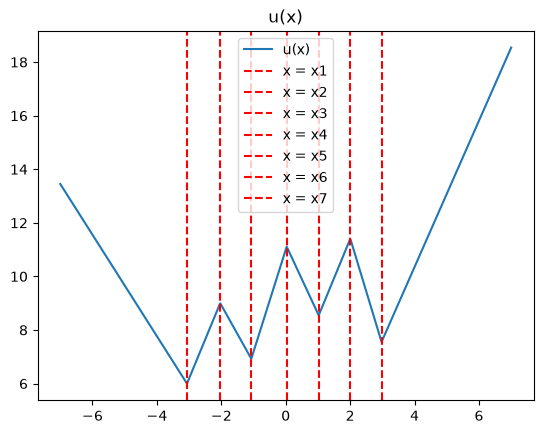

k =  g1


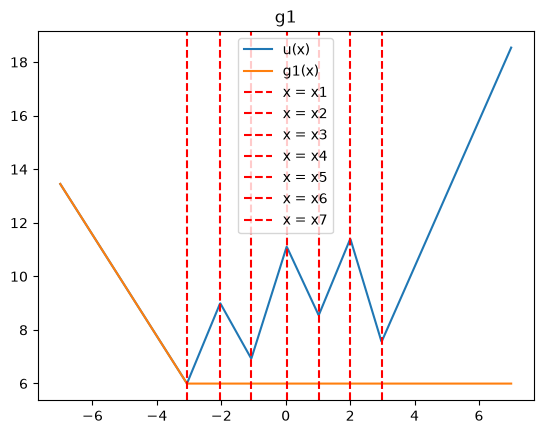

k =  g2


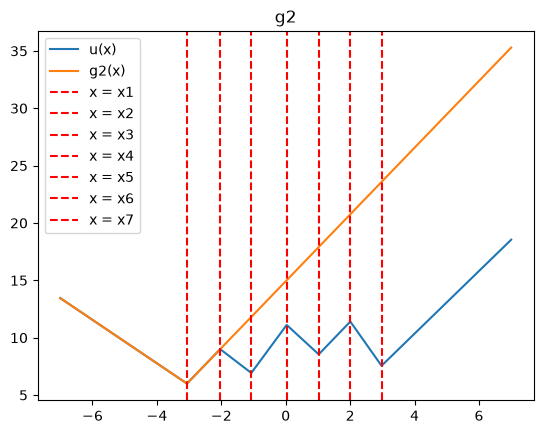

k =  g3


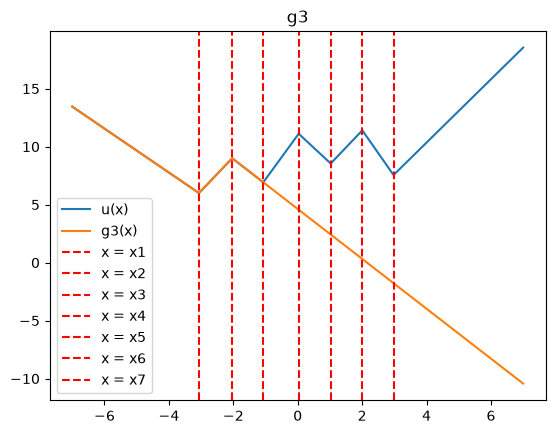

k =  g4


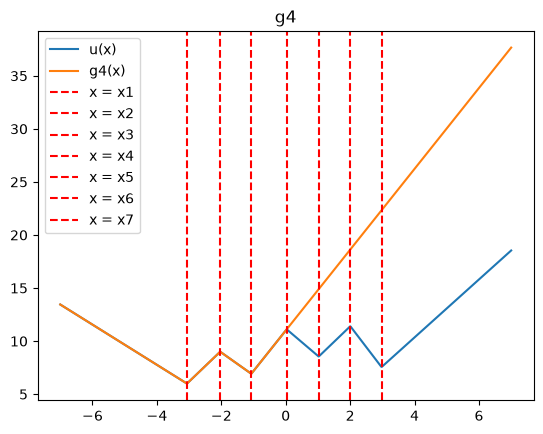

k =  g5


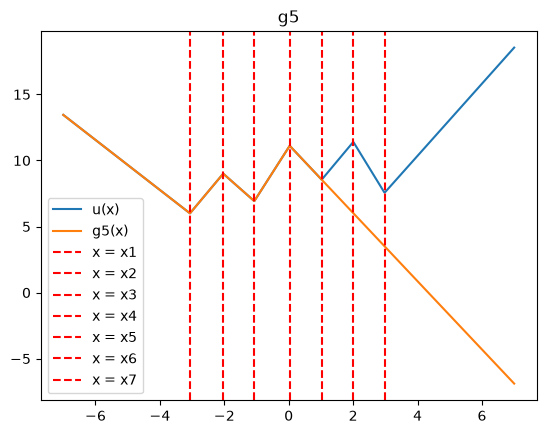

k =  g6


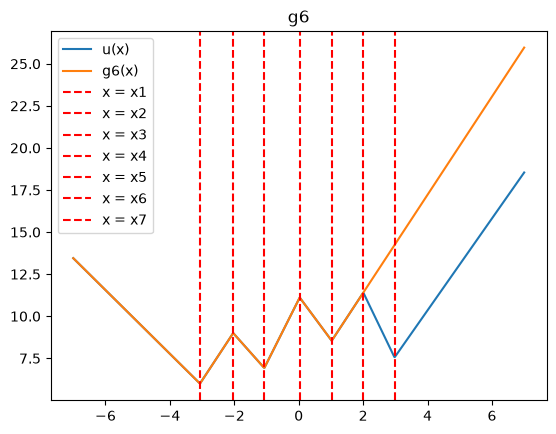

k =  g7


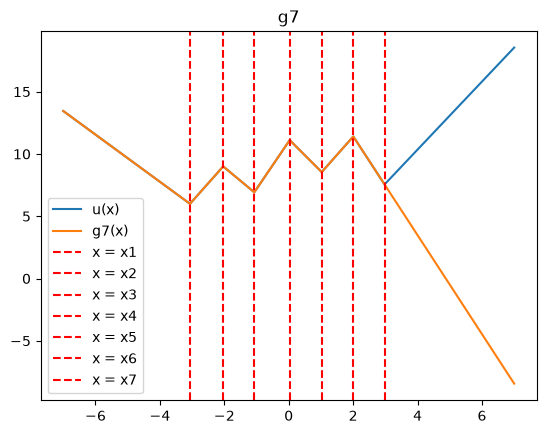

k =  g8


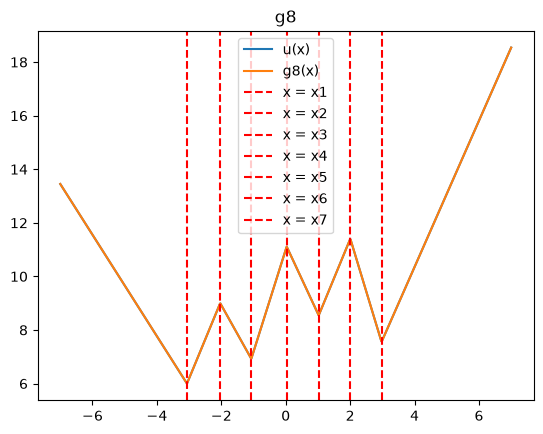

In [6]:
y1 = alpha_vals[0] * sorted_x_i_vals[0] + beta_vals[0]

num_g_i = len(alpha_vals)
print("num_g_i = ", num_g_i)
g_dict = {}
g1 = lambda x : -1.0 * alpha_vals[0] * ReLU( sorted_x_i_vals[0]  - x) + y1
g_dict["g1"] = g1
g2 = lambda x : g1(x) + alpha_vals[1] * ReLU( x - sorted_x_i_vals[0])
g_dict["g2"] = g2
g3 = lambda x : g2(x) + (alpha_vals[2] - alpha_vals[1]) * ReLU( x - sorted_x_i_vals[1])
g_dict["g3"] = g3
if num_g_i > 3:
    i = 2
    g4 = lambda x : g3(x) + (alpha_vals[3] - alpha_vals[2]) * ReLU( x - sorted_x_i_vals[2])
    g_dict["g" + str(i+2)] = g4
if num_g_i > 4:
    i = 3
    g5 = lambda x : g4(x) + (alpha_vals[4] - alpha_vals[3]) * ReLU( x - sorted_x_i_vals[3])
    g_dict["g" + str(i+2)] = g5
if num_g_i > 5:
    i = 4
    g6 = lambda x : g5(x) + (alpha_vals[5] - alpha_vals[4]) * ReLU( x - sorted_x_i_vals[4])
    g_dict["g" + str(i+2)] = g6
if num_g_i > 6:
    i = 5
    g7 = lambda x : g6(x) + (alpha_vals[6] - alpha_vals[5]) * ReLU( x - sorted_x_i_vals[5])
    g_dict["g" + str(i+2)] = g7
if num_g_i > 7:
    i = 6
    g8 = lambda x : g7(x) + (alpha_vals[7] - alpha_vals[6]) * ReLU( x - sorted_x_i_vals[6])
    g_dict["g" + str(i+2)] = g8
if num_g_i > 8:
    i = 7
    g9 = lambda x : g8(x) + (alpha_vals[8] - alpha_vals[7]) * ReLU( x - sorted_x_i_vals[7])
    g_dict["g" + str(i+2)] = g9
if num_g_i > 9:
    i = 8
    g10 = lambda x : g9(x) + (alpha_vals[9] - alpha_vals[8]) * ReLU( x - sorted_x_i_vals[8])
    g_dict["g" + str(i+2)] = g10

this_title = "u(x)"
plt.plot(x_vals, u_vals, label = "u(x)")
plt.axvline(x=sorted_x_i_vals[0], color='red', linestyle='--', linewidth=1.5, label='x = x1')
plt.axvline(x=sorted_x_i_vals[1], color='red', linestyle='--', linewidth=1.5, label='x = x2')
plt.axvline(x=sorted_x_i_vals[2], color='red', linestyle='--', linewidth=1.5, label='x = x3')
plt.axvline(x=sorted_x_i_vals[3], color='red', linestyle='--', linewidth=1.5, label='x = x4')
plt.axvline(x=sorted_x_i_vals[4], color='red', linestyle='--', linewidth=1.5, label='x = x5')
plt.axvline(x=sorted_x_i_vals[5], color='red', linestyle='--', linewidth=1.5, label='x = x6')
plt.axvline(x=sorted_x_i_vals[6], color='red', linestyle='--', linewidth=1.5, label='x = x7')
plt.legend()
plt.title(this_title)
plt.show()

for k in g_dict.keys():
    print("k = ", k)
    g_i = g_dict[k]
    vec_g_i = np.vectorize(g_i)
    g_i_vals = vec_g_i(x_vals)
    this_title = k
    plt.plot(x_vals, u_vals, label = "u(x)")
    plt.plot(x_vals, g_i_vals, label = k + "(x)")
    plt.axvline(x=sorted_x_i_vals[0], color='red', linestyle='--', linewidth=1.5, label='x = x1')
    plt.axvline(x=sorted_x_i_vals[1], color='red', linestyle='--', linewidth=1.5, label='x = x2')
    plt.axvline(x=sorted_x_i_vals[2], color='red', linestyle='--', linewidth=1.5, label='x = x3')
    plt.axvline(x=sorted_x_i_vals[3], color='red', linestyle='--', linewidth=1.5, label='x = x4')
    plt.axvline(x=sorted_x_i_vals[4], color='red', linestyle='--', linewidth=1.5, label='x = x5')
    plt.axvline(x=sorted_x_i_vals[5], color='red', linestyle='--', linewidth=1.5, label='x = x6')
    plt.axvline(x=sorted_x_i_vals[6], color='red', linestyle='--', linewidth=1.5, label='x = x7')
    plt.legend()
    plt.title(this_title)
    plt.show()

### Problem Set 2, Q3 (c)
Define $u(x) = | |x-1| - 2|x+2| |$. Then $u(x)$ is piecewise linear, with
$$u(x) = 
\left\{
\begin{aligned}
-x-5 \quad & : \,\, x \leq -5 \\
x + 5 \quad & : \, -5 \leq x \leq -2 \\
-3x -3 \quad & : \, -2 \leq x \leq -1 \\
3x + 3 \quad & : \, -1 \leq x \leq 1 \\
x + 5 \quad & : \,\, 1 \leq x
\end{aligned}
\right.
$$
Therefore,
$$sorted\_x\_i\_vals = [-5\,, -2\,, -1\,, 1], \quad
alpha\_vals = [-1\,, 1\,, -3\,, 3\,, 1], \quad
beta\_vals = [-5\,, 5\,, -3\,, 3\,, 5]$$
Hence, 
$$g_1(x) = - \alpha_1 ReLU( x_1 - x) + y_1 = ReLU(-5 - x) + 0 = ReLU(-5 - x)$$
$$g_2(x) = g_1 (x) + \alpha_2 ReLU(x - x_1) = g_1 (x) + ReLU(x + 5)$$
$$g_3(x) = g_2 (x) + (\alpha_3 - \alpha_2) ReLU(x - x_2) = g_2 (x) - 4 ReLU(x + 2)$$
$$g_4(x) = g_3 (x) + (\alpha_4 - \alpha_3) ReLU(x - x_3) = g_3 (x) + 6 RelU(x + 1)$$
$$g_5(x) = g_4 (x) + (\alpha_5 - \alpha_4) ReLU(x - x_4) = g_4 (x) - 2 ReLU(x - 1)$$
Putting this all together,
$$u(x) = g_5(x) = 
ReLU(-5 - x)
+ ReLU(x + 5)
- 4 ReLU(x + 2)
+ 6 ReLU(x + 1)
- 2 ReLU(x - 1)$$
This is illustrated below 

In [7]:
sorted_x_i_vals = [-5., -2., -1., 1.]
alpha_vals = [-1., 1., -3., 3., 1.]
beta_vals = [-5., 5., -3., 3., 5.]

min_x_i = sorted_x_i_vals[0]
max_x_i = sorted_x_i_vals[-1]

num_x_vals = 1001
x_vals = np.linspace(min_x_i - 2.0, max_x_i + 2.0, num_x_vals)

i=0
u_vals = np.zeros(len(x_vals))
for x in x_vals:
    u_vals[i] = u(sorted_x_i_vals, alpha_vals, beta_vals, x)
    i +=1

num_g_i =  5


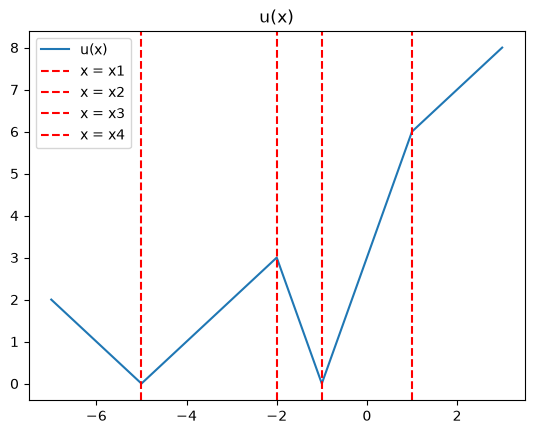

k =  g1


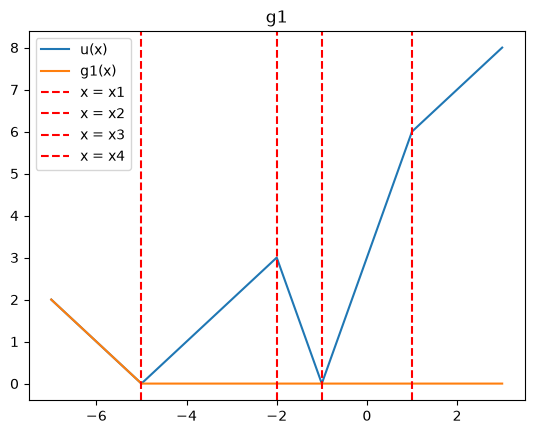

k =  g2


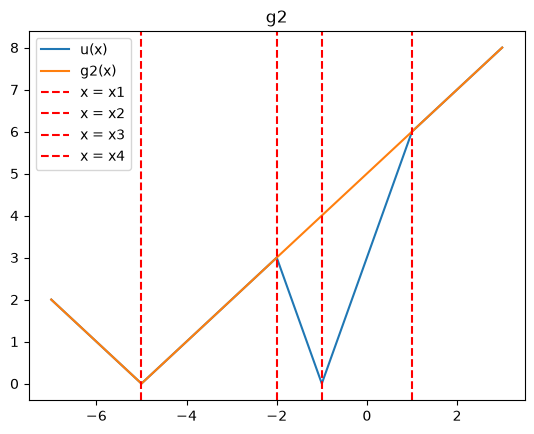

k =  g3


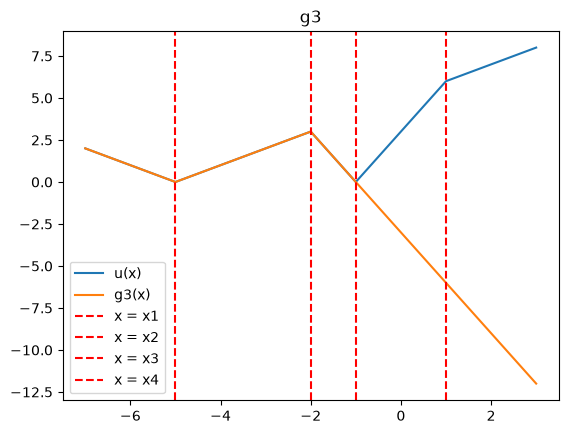

k =  g4


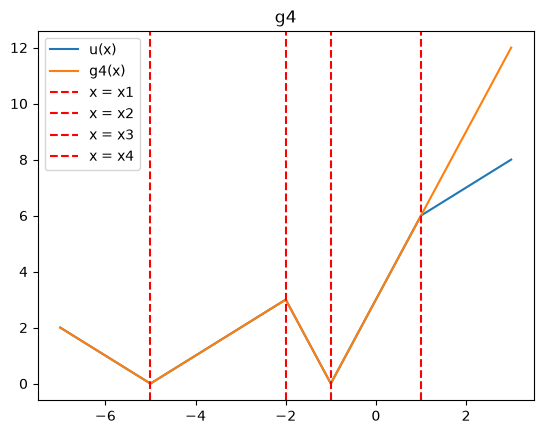

k =  g5


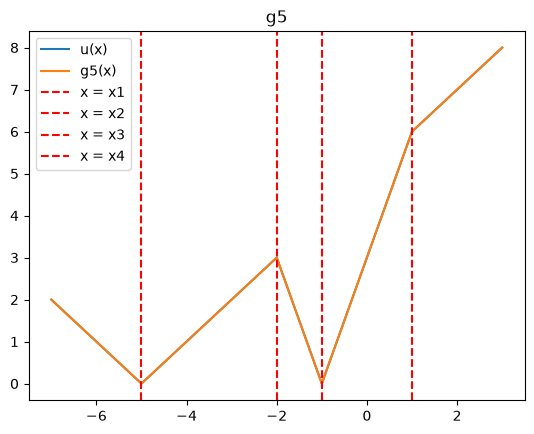

In [8]:
y1 = alpha_vals[0] * sorted_x_i_vals[0] + beta_vals[0]

num_g_i = len(alpha_vals)
print("num_g_i = ", num_g_i)
g_dict = {}
g1 = lambda x : -1.0 * alpha_vals[0] * ReLU( sorted_x_i_vals[0]  - x) + y1
g_dict["g1"] = g1
g2 = lambda x : g1(x) + alpha_vals[1] * ReLU( x - sorted_x_i_vals[0])
g_dict["g2"] = g2
g3 = lambda x : g2(x) + (alpha_vals[2] - alpha_vals[1]) * ReLU( x - sorted_x_i_vals[1])
g_dict["g3"] = g3
if num_g_i > 3:
    i = 2
    g4 = lambda x : g3(x) + (alpha_vals[3] - alpha_vals[2]) * ReLU( x - sorted_x_i_vals[2])
    g_dict["g" + str(i+2)] = g4
if num_g_i > 4:
    i = 3
    g5 = lambda x : g4(x) + (alpha_vals[4] - alpha_vals[3]) * ReLU( x - sorted_x_i_vals[3])
    g_dict["g" + str(i+2)] = g5
if num_g_i > 5:
    i = 4
    g6 = lambda x : g5(x) + (alpha_vals[5] - alpha_vals[4]) * ReLU( x - sorted_x_i_vals[4])
    g_dict["g" + str(i+2)] = g6
if num_g_i > 6:
    i = 5
    g7 = lambda x : g6(x) + (alpha_vals[6] - alpha_vals[5]) * ReLU( x - sorted_x_i_vals[5])
    g_dict["g" + str(i+2)] = g7
if num_g_i > 7:
    i = 6
    g8 = lambda x : g7(x) + (alpha_vals[7] - alpha_vals[6]) * ReLU( x - sorted_x_i_vals[6])
    g_dict["g" + str(i+2)] = g8
if num_g_i > 8:
    i = 7
    g9 = lambda x : g8(x) + (alpha_vals[8] - alpha_vals[7]) * ReLU( x - sorted_x_i_vals[7])
    g_dict["g" + str(i+2)] = g9
if num_g_i > 9:
    i = 8
    g10 = lambda x : g9(x) + (alpha_vals[9] - alpha_vals[8]) * ReLU( x - sorted_x_i_vals[8])
    g_dict["g" + str(i+2)] = g10

this_title = "u(x)"
plt.plot(x_vals, u_vals, label = "u(x)")
plt.axvline(x=sorted_x_i_vals[0], color='red', linestyle='--', linewidth=1.5, label='x = x1')
plt.axvline(x=sorted_x_i_vals[1], color='red', linestyle='--', linewidth=1.5, label='x = x2')
plt.axvline(x=sorted_x_i_vals[2], color='red', linestyle='--', linewidth=1.5, label='x = x3')
plt.axvline(x=sorted_x_i_vals[3], color='red', linestyle='--', linewidth=1.5, label='x = x4')
plt.legend()
plt.title(this_title)
plt.show()

for k in g_dict.keys():
    print("k = ", k)
    g_i = g_dict[k]
    vec_g_i = np.vectorize(g_i)
    g_i_vals = vec_g_i(x_vals)
    this_title = k
    plt.plot(x_vals, u_vals, label = "u(x)")
    plt.plot(x_vals, g_i_vals, label = k + "(x)")
    plt.axvline(x=sorted_x_i_vals[0], color='red', linestyle='--', linewidth=1.5, label='x = x1')
    plt.axvline(x=sorted_x_i_vals[1], color='red', linestyle='--', linewidth=1.5, label='x = x2')
    plt.axvline(x=sorted_x_i_vals[2], color='red', linestyle='--', linewidth=1.5, label='x = x3')
    plt.axvline(x=sorted_x_i_vals[3], color='red', linestyle='--', linewidth=1.5, label='x = x4')
    plt.legend()
    plt.title(this_title)
    plt.show()